<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/reg-1-predicting-a-price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting a home's price

You are pricing a home, as an appraiser, an agent, or a buyer. Sale prices of the 89 single-family homes sold in North Ames, Iowa, in 2007 range from about \$99,000 to \$268,000. What explains that spread? The first thing most people look at is size.

*Data: Ames housing data (De Cock, 2011, Journal of Statistics Education), single-family homes in the North Ames neighborhood sold under normal conditions in 2007, n = 89. Living area is the finished area above ground, in square feet; basements are not included.*

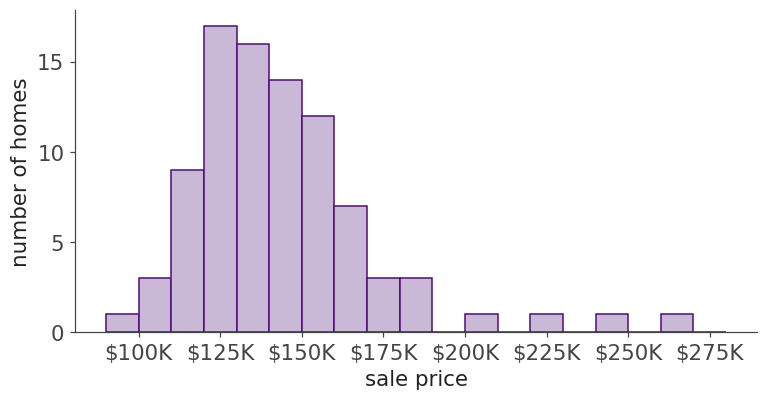

In [26]:
# @title
# ---------------- 1. predicting a price ----------------
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(y, bins=np.arange(90000, 280001, 10000), color=LIGHT, edgecolor=PURPLE)
ax.xaxis.set_major_formatter(DOLLARS); ax.set_xlabel("sale price"); ax.set_ylabel("number of homes")
plt.show()  # f01_price_hist.png

In [27]:
# @title
# Setup: libraries, colors, plotting helpers, and the North Ames data
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch
import scipy.stats as stats


PURPLE, GOLD, GRAY, LIGHT, SAND = "#510C76", "#B07A00", "#6E6E6E", "#C9B8D6", "#EFE3C2"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})
DOLLARS = mtick.FuncFormatter(lambda v, p: "$0" if v == 0 else ("−" if v < 0 else "") + f"${abs(v)/1000:,.0f}K")


def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1


def home_axes(ax, xlim=(700, 2400), ylim=(0, 290000)):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(DOLLARS)
    ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")


na = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
x, y = na.area.values.astype(float), na.price.values.astype(float)
n = len(na)


# a fixed subset of 15 homes for the pictures with error segments
rng = np.random.default_rng(640)
sub = na.iloc[np.sort(rng.choice(n, 15, replace=False))]
xs_, ys_ = sub.area.values.astype(float), sub.price.values.astype(float)
a_s, b_s = fit(xs_, ys_)


def box(ax, cx, cy, w, h, text, ec=PURPLE, fc="white", fs=13):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs)
def arrow(ax, p, q, color=PURPLE):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

plt.rcParams["figure.dpi"] = 110

## Bigger homes, higher prices

We use a scatterplot to visualize the relationship between  square footage and selling price. Larger homes tend to sell for more, but homes of the same size sell for quite different prices. Notice the two large homes at the top right; we will see them again.

We use one neighborhood and one year on purpose. Why that matters comes up when we talk about the assumptions behind regression.

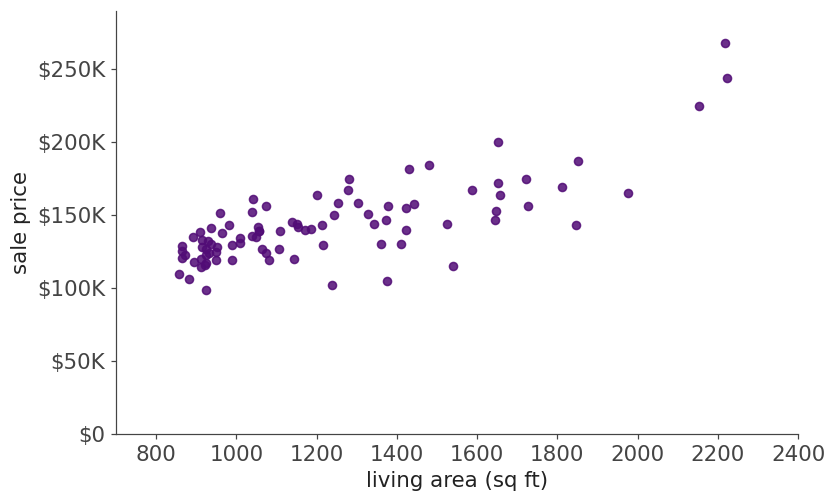

In [28]:
# @title

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color=PURPLE, s=28, alpha=0.85)
home_axes(ax)
plt.show()

##Finding the best line


## Deterministic and probabilistic models

A mathematical model is an equation that describes a real-world process, usually in a simplified way. There are two types of models: deterministic and probabilistic. A **deterministic** model gives the exact value of the outcome once the inputs are known. Such models are common in physics and finance: distance = speed $\times$ time, or the interest due on a fixed-rate loan. A **probabilistic** (also called stochastic) model describes both the typical outcome and how much individual outcomes vary around it. Such models are common wherever the outcome depends on many factors we cannot observe: sales, demand, delivery times, prices.

The models we study are linear models: the mean of y is a linear combination of the x-variables. In simple linear regression, where we have only one x-variable, it means that to predict the mean of y, we are multiplying the value of x by a constant (i.e., a number), and adding another constant to that product.

Other models exist, such as nonlinear growth curves, decision trees, and neural networks, but linear models are the foundation. ANOVA is a linear model, logistic regression is a generalized linear model, and neural networks are built from layers of linear combinations.

*All models are wrong, but some are useful (George Box).*

## The parts of the linear  model

$$y = \beta_0 + \beta_1 x + \varepsilon$$

- $y$ is the **dependent**, aka **response** variable, the one we want to predict: sale price.
- $x$ is the **independent**, aka **explanatory** variable, the one we predict from: living area.
- $\beta_0$ (intercept) and $\beta_1$ (slope) describe the population line. Like $\mu$, they are unknown, and we estimate them from a sample.
- $\varepsilon$ is the random error.

"Independent variable" here only means the variable on the x-axis. It has nothing to do with statistical independence.

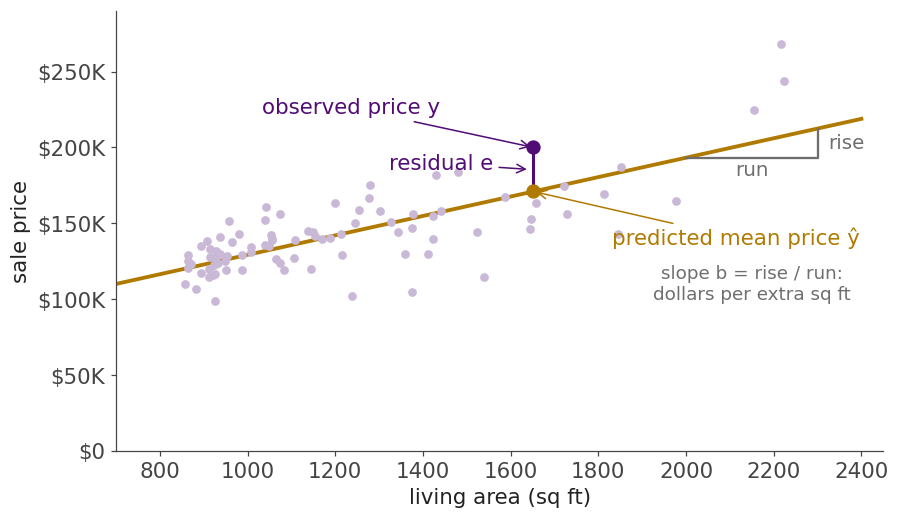

In [33]:
# @title
# anatomy of the model
b0, b1 = fit(x, y)
yhat = b0 + b1 * x
res = y - yhat
s = np.sqrt(np.sum(res ** 2) / (n - 2))
xbar, ybar = x.mean(), y.mean()
ssxx = np.sum((x - xbar) ** 2)

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2.5)
ax.scatter(x, y, color=LIGHT, s=22, zorder=2)
i = int(np.argmax(res * (x > 1300) * (x < 1700)))
xi, yi, yhi = x[i], y[i], yhat[i]
ax.scatter([xi], [yi], color=PURPLE, s=70, zorder=4)
ax.scatter([xi], [yhi], color=GOLD, s=70, zorder=4)
ax.plot([xi, xi], [yhi, yi], color=PURPLE, lw=2)
ax.annotate("observed price y", xy=(xi, yi), xytext=(xi - 620, yi + 22000), color=PURPLE,
            arrowprops=dict(arrowstyle="->", color=PURPLE))
ax.annotate("predicted mean price ŷ", xy=(xi, yhi), xytext=(xi + 180, yhi - 35000), color=GOLD,
            arrowprops=dict(arrowstyle="->", color=GOLD))
ax.annotate("residual e", xy=(xi - 8, (yi + yhi) / 2), xytext=(xi - 330, (yi + yhi) / 2), color=PURPLE,
            arrowprops=dict(arrowstyle="->", color=PURPLE))
x1, x2 = 2000, 2300
ax.plot([x1, x2, x2], [b0 + b1 * x1, b0 + b1 * x1, b0 + b1 * x2], color=GRAY, lw=1.5)
ax.text((x1 + x2) / 2, b0 + b1 * x1 - 12000, "run", ha="center", color=GRAY, fontsize=13)
ax.text(x2 + 25, b0 + b1 * (x1 + x2) / 2, "rise", color=GRAY, fontsize=13, va="center")
ax.text(2150, 100000, "slope b = rise / run:\ndollars per extra sq ft", ha="center", color=GRAY, fontsize=12)
home_axes(ax, xlim=(700, 2450))
plt.show()  #

## Parameters, random variables, and estimates

| | Population value (fixed, unknown) | Random variable (before the sample is drawn) | Observed value (after the sample is drawn) |
|---|---|---|---|
| Dependent variable, for observation $i$ | | $Y_i$ | $y_i$ |
| Explanatory variable, for observation $i$ | | $X_i$ (in regression usually treated as given) | $x_i$ |
| Mean of $X$ | $\mu_X$ | $\bar{X}$ | $\bar{x}$ |
| Standard deviation of $X$ | $\sigma_X$ | $S_X$ | $s_x$ |
| Intercept | $\beta_0$ | $b_0$ | $b_0$ |
| Slope | $\beta_1$ | $b_1$ | $b_1$ |
| Error | | $\varepsilon$, never observed | $e_i = y_i - \hat{y}_i$, the residual |
| Standard deviation of the error | $\sigma_\varepsilon$ | $s_e$ | $s_e$ |

A parameter such as $\beta_1$ is one fixed number that we do not know. Before we collect the data, the slope we will compute is a random variable: a different sample would give a different value, and its distribution is what tests and intervals are built on. After we collect the data, it is one number, our estimate. For the mean we can tell the two apart by the capital letter, $\bar{X}$ versus $\bar{x}$. For the slope, the intercept, and $s_e$, the same symbol is used for both.

Our textbook writes $b_0$ and $b_1$. Many other books write $\hat{\beta}_0$ and $\hat{\beta}_1$; the hat means "estimate of," and the two notations mean the same thing. Our textbook and Excel write $s_e$ simply as $s$. We keep the subscript to tell it apart from $s_y$, the ordinary standard deviation of $y$. The residual $e$ is not an estimate of a parameter: it is the observed stand-in for the error $\varepsilon$, which we never see.

##Finding the best line
Which of these lines is best? To compare lines we need to collapse all the vertical distances into one number. Each vertical segment is a **residual**, $e = y - \hat{y}$: the observed price minus the price the line predicts.

To keep the pictures readable, we use 15 of the 89 homes here. Consider the following three lines:

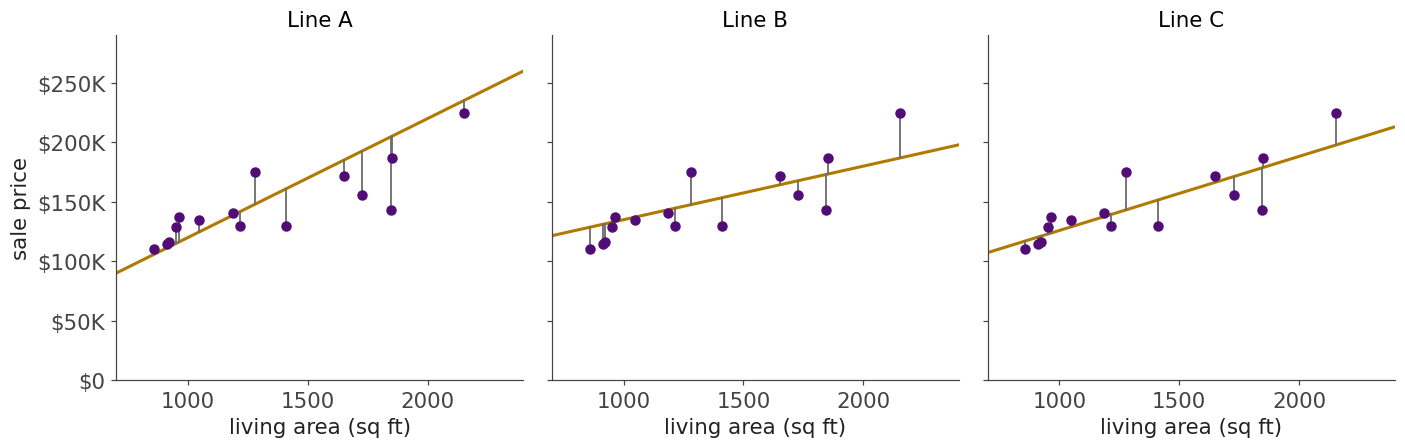

In [32]:
# ---------------- 2. what does the best line mean ----------------
cands = [("Line A", 20000, 100.0), ("Line B", 90000, 45.0), ("Line C", a_s, b_s)]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3), sharey=True)
for ax, (nm, a, b) in zip(axs, cands):
    ax.plot(XS, a + b * XS, color=GOLD, lw=2)
    for xi, yi in zip(xs_, ys_):
        ax.plot([xi, xi], [yi, a + b * xi], color=GRAY, lw=1.2)
    ax.scatter(xs_, ys_, color=PURPLE, s=34, zorder=3)
    ax.set_title(nm); home_axes(ax)
    if ax is not axs[0]: ax.set_ylabel("")
fig.tight_layout(); plt.show()